# [13.6] Autoregressive Image Tokens (exercises)

> **Colab:
> [exercises](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter13_image_generation_interpretability/exercises/part6_autoregressive_image_tokens/13.6_Autoregressive_Image_Tokens_exercises.ipynb) |
> [solutions](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter13_image_generation_interpretability/exercises/part6_autoregressive_image_tokens/13.6_Autoregressive_Image_Tokens_solutions.ipynb)**

This section is part of the ARENA extension. The solutions notebook is saved with all of its outputs, so you can use it as a reference for what every cell should produce.

You can collapse each section so only the headers are visible, by clicking the arrow symbol on the left hand side of the markdown header cells.

<img src="https://raw.githubusercontent.com/info-arena/ARENA_img/main/misc/headers/header-13-2.png" width="350">

# Introduction

An image is generated as sixteen color tokens. Change the first red-square token to blue.
If you decode the edited token grid, one small patch turns blue. If you regenerate the future
autoregressively, the entire square can turn blue. Why are these two interventions different?

By the end of this notebook, you will have shown that causal continuation can amplify a
one-token image edit in an explicit copy-attention organism, because decoded-pixel IoU for
the blue square is1 after regeneration,0.25 for a local token replacement, and0 for a
wrong-region edit. The visible result is an image grid, spatial token grid and causal attention map.

Prerequisites: causal attention from chapter1, vector quantization and array indexing. We use
a known RGB codebook and a fixed attention program, not a trained VQ-VAE or autoregressive
transformer. The VQ loss and straight-through gradients are implemented and checked without
running an optimizer.

## Study-edition boundary

The default path is a small, deterministic CPU organism with explicit weights and finite
images. It teaches the named component operations and controls. It is not a trained diffusion
model, a pretrained checkpoint, or a paper replication. No model download, GPU selection,
training run or scientific sweep occurs.

## Content & Learning Objectives

### 1️⃣ An image vocabulary

Quantize small image patches and inspect the image vocabulary.

> ##### Learning Objectives
>
> - Implement the visible operations for quantize small image patches and inspect the image vocabulary.
> - Explain the tensor axes and use an independent small-case check.

### 2️⃣ What quantization learns and loses

Measure code usage, quantization error and the VQ learning objective.

> ##### Learning Objectives
>
> - Implement the visible operations for measure code usage, quantization error and the vq learning objective.
> - Explain the tensor axes and use an independent small-case check.

### 3️⃣ A causal attention generator

Implement a causal token generator and compare it with an unconditional baseline.

> ##### Learning Objectives
>
> - Implement the visible operations for implement a causal token generator and compare it with an unconditional baseline.
> - Explain the tensor axes and use an independent small-case check.

### 4️⃣ Local edits and regenerated futures

Patch image tokens, decode the changed content and evaluate locality.

> ##### Learning Objectives
>
> - Implement the visible operations for patch image tokens, decode the changed content and evaluate locality.
> - Explain the tensor axes and use an independent small-case check.

### ☆ Bonus

Anomaly hunts, the source-grounded model bridge, and further reading.

## Setup code

Use the existing environment and keep the notebook under this checkout. No installation cell
is needed. All arrays use NumPy float64 on CPU. The section-local helpers provide plotting
only; each method, metric, intervention and control is implemented below.

In [ ]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

chapter = "chapter13_image_generation_interpretability"
section = "part6_autoregressive_image_tokens"
root_dir = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / chapter).is_dir())
exercises_dir = root_dir / chapter / "exercises"
if str(exercises_dir) not in sys.path:
    sys.path.insert(0, str(exercises_dir))
import part6_autoregressive_image_tokens.tests as tests
import part6_autoregressive_image_tokens.utils as utils
MAIN = __name__ == "__main__"

# 1️⃣ An image vocabulary

> ##### Learning Objectives
>
> - Implement the visible operations for quantize small image patches and inspect the image vocabulary.
> - Explain the tensor axes and use an independent small-case check.

Vector quantization maps each continuous patch representation to its nearest codebook row.
Here the encoder is just patch-mean RGB. Each2x2 patch becomes one3-vector; the codebook has
three RGB rows: gray, red and blue. A4x4 token grid decodes to an8x8 image.
This exact color vocabulary lets us see code meaning without treating an untrained neural
network as an image tokenizer.

Use squared Euclidean distance and break ties by the smallest code ID. Keep the codebook
order fixed: `[gray, red, blue]`. Changing ID order without changing the prior is a meaningful
interface bug, not a new vocabulary.

### Exercise - implement `patch_means`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 5-10 minutes on this exercise.
> ```

Return `[grid_h,grid_w,3]` patch means. The encoder compresses within-patch detail before quantization.

In [ ]:
def patch_means(image, patch_size):
    raise NotImplementedError()


tests.test_patch_means(patch_means)

<details><summary>Hint</summary>

Average the within-patch axes only.

</details>

<details><summary>Expected output</summary>

The immediate analytic checks print `All tests in test_patch_means passed!`.
A checkerboard can have the same patch mean as a flat patch: this encoder is intentionally lossy.

</details>


<details><summary>Solution</summary>

```python
def patch_means(image, patch_size):
    h,w,c=np.asarray(image).shape
    if h%patch_size or w%patch_size:
        raise ValueError("nondivisible image geometry")
    return np.asarray(image).reshape(h//patch_size,patch_size,w//patch_size,patch_size,c).mean(axis=(1,3))
```
</details>

### Exercise - implement `nearest_codes`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 5-10 minutes on this exercise.
> ```

Return the nearest code ID for every vector, preserving all leading axes.

In [ ]:
def nearest_codes(vectors, codebook):
    raise NotImplementedError()


tests.test_nearest_codes(nearest_codes)

<details><summary>Hint</summary>

Broadcast a codebook axis before the final RGB axis.

</details>

<details><summary>Expected output</summary>

The immediate analytic checks print `All tests in test_nearest_codes passed!`.
A tie between two colors chooses the smaller code ID.

</details>


<details><summary>Solution</summary>

```python
def nearest_codes(vectors, codebook):
    distances=((np.asarray(vectors)[...,None,:]-np.asarray(codebook))**2).sum(axis=-1)
    return distances.argmin(axis=-1)
```
</details>

### Exercise - implement `decode_tokens`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 5-10 minutes on this exercise.
> ```

Decode a2D code grid into constant-color RGB patches.

In [ ]:
def decode_tokens(code_grid, codebook, patch_size):
    raise NotImplementedError()


tests.test_decode_tokens(decode_tokens)

<details><summary>Hint</summary>

Each token expands along both spatial axes.

</details>

<details><summary>Expected output</summary>

The immediate analytic checks print `All tests in test_decode_tokens passed!`.
A2x3 code grid with p2 gives a4x6 RGB image.

</details>


<details><summary>Solution</summary>

```python
def decode_tokens(code_grid, codebook, patch_size):
    return np.asarray(codebook)[np.asarray(code_grid,dtype=int)].repeat(patch_size,axis=0).repeat(patch_size,axis=1)
```
</details>


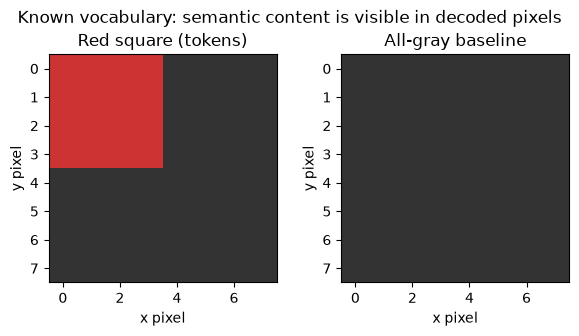

In [ ]:
codebook=np.array([[.2,.2,.2],[.8,.2,.2],[.2,.2,.8]])
layout=np.zeros((4,4),bool);layout[:2,:2]=True
red_grid=np.where(layout,1,0)
red_image=decode_tokens(red_grid,codebook,2)
encoded=nearest_codes(patch_means(red_image,2),codebook)
print("Re-encoded token grid:");print(encoded)
utils.image_grid([red_image,decode_tokens(np.zeros((4,4),int),codebook,2)], ["Red square (tokens)","All-gray baseline"],"Known vocabulary: semantic content is visible in decoded pixels")
plt.show()

<details><summary>Help - how should I interpret this?</summary>

The4x4 IDs have a2x2 block of1s at upper left and0 elsewhere. Decode/encode roundtrip is exact for these solid-color patches. This establishes a finite vocabulary contract; it does not establish learned compression quality.

</details>

## Summary of 1️⃣

An image vocabulary has a geometric decoder and a stable ID contract. A perfect roundtrip on codebook colors says little about arbitrary images.

# 2️⃣ What quantization learns and loses

> ##### Learning Objectives
>
> - Implement the visible operations for measure code usage, quantization error and the vq learning objective.
> - Explain the tensor axes and use an independent small-case check.

A VQ-VAE separates reconstruction learning, codebook learning and commitment. With encoder
outputs $z_e$ and selected codebook vectors $z_q$, the two VQ terms are
$$L_{VQ}=\|\mathrm{sg}(z_e)-z_q\|^2+\beta\|z_e-\mathrm{sg}(z_q)\|^2.$$
We average each squared norm over all entries. `sg` is stop-gradient: the two terms have the
same numerical residual but send gradients to different parameters. The straight-through
value $z_e+\mathrm{sg}(z_q-z_e)$ equals $z_q$ forward and passes decoder gradients to $z_e$.

The small PyTorch gradient fixtures below check this distinction. They do not train a neural
encoder, codebook or decoder. A real VQ-VAE also needs a reconstruction objective and a
learned encoder/decoder, which this finite color quantizer deliberately does not provide.

In [ ]:
import torch as t

### Exercise - implement `vq_objective`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 5-10 minutes on this exercise.
> ```

Implement the two VQ terms with the correct gradient routes. Inputs are small CPU tensors.

In [ ]:
def vq_objective(encoder_values, quantized_values, commitment=0.25):
    raise NotImplementedError()


tests.test_vq_objective(vq_objective)

<details><summary>Hint</summary>

Use detach on different inputs in the two terms.

</details>

<details><summary>Expected output</summary>

The immediate analytic checks print `All tests in test_vq_objective passed!`.
The tests check both loss value and independent encoder/codebook gradients.

</details>


<details><summary>Solution</summary>

```python
def vq_objective(encoder_values, quantized_values, commitment=0.25):
    codebook_loss=(encoder_values.detach()-quantized_values).square().mean()
    commitment_loss=(encoder_values-quantized_values.detach()).square().mean()
    return codebook_loss+commitment*commitment_loss
```
</details>

### Exercise - implement `straight_through_quantized`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 5-10 minutes on this exercise.
> ```

Return the quantized forward value with identity gradient to the encoder and no gradient to codebook values through this branch.

In [ ]:
def straight_through_quantized(encoder_values, quantized_values):
    raise NotImplementedError()


tests.test_straight_through_quantized(straight_through_quantized)

<details><summary>Hint</summary>

Detach the difference, not the entire result.

</details>

<details><summary>Expected output</summary>

The immediate analytic checks print `All tests in test_straight_through_quantized passed!`.
Backpropagating the sum gives encoder gradient1 for every entry.

</details>


<details><summary>Solution</summary>

```python
def straight_through_quantized(encoder_values, quantized_values):
    return encoder_values+(quantized_values-encoder_values).detach()
```
</details>

### Exercise - implement `code_usage`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 5-10 minutes on this exercise.
> ```

Return vocabulary counts and entropy perplexity `exp(H)`. Ignore zero-probability terms in the entropy sum.

In [ ]:
def code_usage(codes, vocabulary_size):
    raise NotImplementedError()


tests.test_code_usage(code_usage)

<details><summary>Hint</summary>

Uniform use ofK codes gives perplexityK; collapse to one code gives1.

</details>

<details><summary>Expected output</summary>

The immediate analytic checks print `All tests in test_code_usage passed!`.
Unused codes must remain visible in the returned count vector.

</details>


<details><summary>Solution</summary>

```python
def code_usage(codes, vocabulary_size):
    counts=np.bincount(np.asarray(codes,dtype=int).ravel(),minlength=vocabulary_size)
    probabilities=counts/counts.sum()
    used=probabilities>0
    perplexity=float(np.exp(-(probabilities[used]*np.log(probabilities[used])).sum()))
    return counts,perplexity
```
</details>

### Exercise - implement `quantization_mse`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 5-10 minutes on this exercise.
> ```

Compute per-entry continuous-vector reconstruction MSE after nearest-code assignment.

In [ ]:
def quantization_mse(vectors, codes, codebook):
    raise NotImplementedError()


tests.test_quantization_mse(quantization_mse)

<details><summary>Hint</summary>

The metric reads the original continuous vectors, not code ID distance.

</details>

<details><summary>Expected output</summary>

The immediate analytic checks print `All tests in test_quantization_mse passed!`.
Low error and high code usage are separate diagnostics.

</details>


<details><summary>Solution</summary>

```python
def quantization_mse(vectors, codes, codebook):
    return float(np.mean((np.asarray(vectors)-np.asarray(codebook)[np.asarray(codes,dtype=int)])**2))
```
</details>


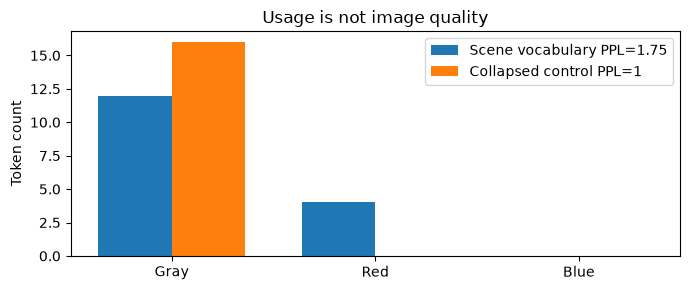

In [ ]:
counts,perplexity=code_usage(encoded,3)
collapsed_counts,collapsed_perplexity=code_usage(np.zeros_like(encoded),3)
print("Code counts:",counts,"perplexity:",round(perplexity,6))
print("Collapsed counts:",collapsed_counts,"perplexity:",collapsed_perplexity)
print("Quantization MSE:",quantization_mse(patch_means(red_image,2),encoded,codebook))
fig,ax=plt.subplots(figsize=(7,3));positions=np.arange(3)
ax.bar(positions-.18,counts,width=.36,label=f"Scene vocabulary PPL={perplexity:.2f}")
ax.bar(positions+.18,collapsed_counts,width=.36,label="Collapsed control PPL=1")
ax.set(xticks=positions,xticklabels=["Gray","Red","Blue"],ylabel="Token count",title="Usage is not image quality");ax.legend();fig.tight_layout();plt.show()

<details><summary>Help - how should I interpret this?</summary>

The scene uses12 gray and4 red codes, with perplexity about1.754765; blue is unused in this one image. The all-gray control has perplexity1 but zero vocabulary-roundtrip error for gray patches. A usage score alone cannot certify meaningful generated content.

</details>

## Summary of 2️⃣

Quantizer gradients, distortion and code usage answer different questions. Learned visual tokenizers require all three to be measured on a declared data role.

# 3️⃣ A causal attention generator

> ##### Learning Objectives
>
> - Implement the visible operations for implement a causal token generator and compare it with an unconditional baseline.
> - Explain the tensor axes and use an independent small-case check.

Autoregression factorizes $p(z_1,\ldots,z_T\mid c)=\prod_t p(z_t\mid c,z_{<t})$.
A full-sequence attention implementation must mask future keys **before** softmax; masking
afterward leaves normalization leakage. Our explicit prior knows a fixed object-layout mask.
At an object position it uses a copy-attention head to read the most recent object token,
or the initial color condition if no object has appeared. At background positions it emits0.

This is an untrained causal attention program with a supplied layout, not a learned image
transformer. Its advantage is that we can identify exactly where a donor color propagates.
The condition is an extra prefix entry, not one of the sixteen image positions.

### Exercise - implement `causal_attention`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 5-10 minutes on this exercise.
> ```

Return outputs and weights for equal-length self-attention. Causal attention includes the current token but excludes all future tokens.

In [ ]:
def causal_attention(queries, keys, values):
    raise NotImplementedError()


tests.test_causal_attention(causal_attention)

<details><summary>Hint</summary>

The upper triangle must have exactly zero weight.

</details>

<details><summary>Expected output</summary>

The immediate analytic checks print `All tests in test_causal_attention passed!`.
Changing a future value must not change any earlier output.

</details>


<details><summary>Solution</summary>

```python
def causal_attention(queries, keys, values):
    scores=np.asarray(queries) @ np.asarray(keys).T / np.sqrt(np.asarray(queries).shape[-1])
    allowed=np.tril(np.ones(scores.shape,dtype=bool))
    scores=np.where(allowed,scores,-np.inf)
    weights=np.exp(scores-scores.max(axis=-1,keepdims=True))
    weights/=weights.sum(axis=-1,keepdims=True)
    return weights @ np.asarray(values),weights
```
</details>

### Exercise - implement `next_token_logits`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 5-10 minutes on this exercise.
> ```

Use the copy-attention mechanism above to return `[vocabulary]` logits. The+1 source offset accounts for the prefix condition. Background positions emit gray.

In [ ]:
def next_token_logits(prefix, position, object_layout, vocabulary_size=3):
    raise NotImplementedError()


tests.test_next_token_logits(next_token_logits)

<details><summary>Hint</summary>

Only the final attention query selects the source; all keys in the provided prefix are causally available.

</details>

<details><summary>Expected output</summary>

The immediate analytic checks print `All tests in test_next_token_logits passed!`.
The attention source for the second object token is the first image token, not the condition entry.

</details>


<details><summary>Solution</summary>

```python
def next_token_logits(prefix, position, object_layout, vocabulary_size=3):
    layout=np.asarray(object_layout,dtype=bool).ravel()
    if not layout[position]:
        logits=np.zeros(vocabulary_size);logits[0]=20.
        return logits
    prior_objects=np.flatnonzero(layout[:position])
    source=int(prior_objects[-1]+1) if len(prior_objects) else 0
    length=len(prefix)
    queries=np.zeros((length,length));queries[-1,source]=100*np.sqrt(length)
    keys=np.eye(length)
    values=np.eye(vocabulary_size)[np.asarray(prefix,dtype=int)]
    output,_=causal_attention(queries,keys,values)
    return 20*output[-1]
```
</details>

### Exercise - implement `greedy_image_tokens`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 5-10 minutes on this exercise.
> ```

Generate the image in raster order, feeding your own chosen token back each step. Do not use the ground-truth image tokens.

In [ ]:
def greedy_image_tokens(condition, object_layout, vocabulary_size=3):
    raise NotImplementedError()


tests.test_greedy_image_tokens(greedy_image_tokens)

<details><summary>Hint</summary>

Strip the condition only after the continuation is complete.

</details>

<details><summary>Expected output</summary>

The immediate analytic checks print `All tests in test_greedy_image_tokens passed!`.
Conditions red1 and blue2 produce the same shape with different colors.

</details>


<details><summary>Solution</summary>

```python
def greedy_image_tokens(condition, object_layout, vocabulary_size=3):
    prefix=[int(condition)]
    for position in range(np.asarray(object_layout).size):
        logits=next_token_logits(prefix,position,object_layout,vocabulary_size)
        prefix.append(int(np.argmax(logits)))
    return np.array(prefix[1:]).reshape(np.asarray(object_layout).shape)
```
</details>


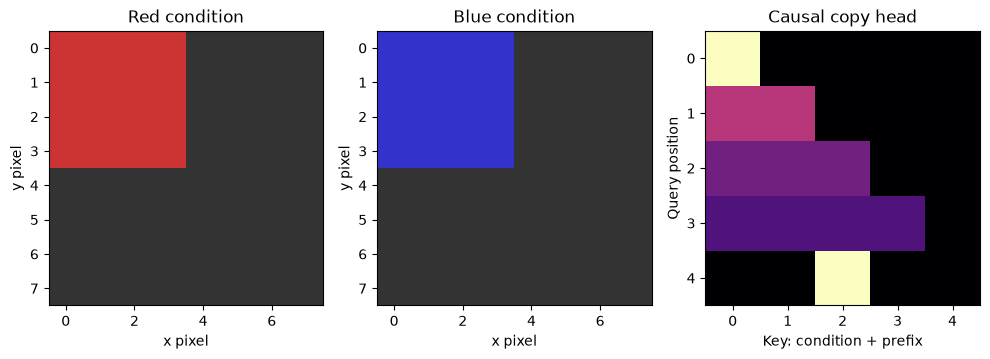

In [ ]:
generated_red=greedy_image_tokens(1,layout)
generated_blue=greedy_image_tokens(2,layout)
print("Red and blue grids:");print(generated_red);print(generated_blue)
# Inspect the copy head just before the third object position (raster position4).
prefix=[1]+generated_red.ravel()[:4].tolist()
queries=np.zeros((5,5));queries[-1,2]=100*np.sqrt(5)
_,head_weights=causal_attention(queries,np.eye(5),np.eye(3)[prefix])
fig,axes=plt.subplots(1,3,figsize=(10,3.5))
axes[0].imshow(decode_tokens(generated_red,codebook,2));axes[0].set(title="Red condition",xlabel="x pixel",ylabel="y pixel")
axes[1].imshow(decode_tokens(generated_blue,codebook,2));axes[1].set(title="Blue condition",xlabel="x pixel",ylabel="y pixel")
axes[2].imshow(head_weights,vmin=0,vmax=1,cmap='magma');axes[2].set(title="Causal copy head",xlabel="Key: condition + prefix",ylabel="Query position")
fig.tight_layout();plt.show()

<details><summary>Help - how should I interpret this?</summary>

The complete generated images contain structured squares, not noise. That content is supplied by the layout and copy program, so it is not evidence of learned image structure. The final attention row points to the latest object token; the upper triangle is exactly zero. The attention map identifies a causal route that the next part will edit.

</details>

## Summary of 3️⃣

Causal masking prevents future leakage; autoregressive feedback makes earlier tokens potential causes of later tokens. A supplied layout must remain visible as an assumption.

# 4️⃣ Local edits and regenerated futures

> ##### Learning Objectives
>
> - Implement the visible operations for patch image tokens, decode the changed content and evaluate locality.
> - Explain the tensor axes and use an independent small-case check.

There are two distinct interventions. A local edit replaces one token **after** generation,
then decodes the entire grid. A prefix intervention forces one token **during** generation and
recomputes all later tokens. Only the latter follows downstream model dependencies.

Score the resulting images with an independent blue-pixel mask: blue minus red greater than0.3.
The target mask is the supplied square repeated to pixel resolution. Report intersection over
union with this target and count changed pixels outside the forced token's2x2 region.

**Make a prediction first:** which intervention changes the entire square? Will a blue donor
placed in the last background token improve the blue-square IoU? A colored patch outside the
object should fail the task even though it is visibly blue.

### Exercise - implement `regenerate_with_patch`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 5-10 minutes on this exercise.
> ```

Force one raster image token to the donor ID, then regenerate the future using the edited prefix.

In [ ]:
def regenerate_with_patch(condition, object_layout, patch_position, donor_token, vocabulary_size=3):
    raise NotImplementedError()


tests.test_regenerate_with_patch(regenerate_with_patch)

<details><summary>Hint</summary>

Recomputing only the patched token is a local edit, not this intervention.

</details>

<details><summary>Expected output</summary>

The immediate analytic checks print `All tests in test_regenerate_with_patch passed!`.
Patching the first object token can change all later object tokens; background positions remain gray.

</details>


<details><summary>Solution</summary>

```python
def regenerate_with_patch(condition, object_layout, patch_position, donor_token, vocabulary_size=3):
    prefix=[int(condition)]
    for position in range(np.asarray(object_layout).size):
        token=int(donor_token) if position==patch_position else int(np.argmax(next_token_logits(prefix,position,object_layout,vocabulary_size)))
        prefix.append(token)
    return np.array(prefix[1:]).reshape(np.asarray(object_layout).shape)
```
</details>

### Exercise - implement `blue_mask_iou`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 5-10 minutes on this exercise.
> ```

Read a blue-object segmentation from decoded pixels, then compute IoU. Do not score code IDs directly.

In [ ]:
def blue_mask_iou(image, truth_mask):
    raise NotImplementedError()


tests.test_blue_mask_iou(blue_mask_iou)

<details><summary>Hint</summary>

The donor color changes a pixel-level red-blue contrast.

</details>

<details><summary>Expected output</summary>

The immediate analytic checks print `All tests in test_blue_mask_iou passed!`.
A single blue patch inside a four-patch target gives IoU0.25.

</details>


<details><summary>Solution</summary>

```python
def blue_mask_iou(image, truth_mask):
    predicted=np.asarray(image)[...,2]-np.asarray(image)[...,0] > .3
    truth=np.asarray(truth_mask,dtype=bool)
    union=np.count_nonzero(predicted|truth)
    return float(np.count_nonzero(predicted&truth)/union) if union else 1.0
```
</details>

### Exercise - implement `outside_patch_changes`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 5-10 minutes on this exercise.
> ```

Count changed pixels outside the directly forced token region. This is a downstream influence count, not automatically unwanted damage.

In [ ]:
def outside_patch_changes(reference_image, edited_image, patch_mask):
    raise NotImplementedError()


tests.test_outside_patch_changes(outside_patch_changes)

<details><summary>Hint</summary>

Count spatial pixels once, not changed RGB channels.

</details>

<details><summary>Expected output</summary>

The immediate analytic checks print `All tests in test_outside_patch_changes passed!`.
For a2x2 token, four pixels can change with zero outside-region changes.

</details>


<details><summary>Solution</summary>

```python
def outside_patch_changes(reference_image, edited_image, patch_mask):
    changed=np.any(np.abs(np.asarray(edited_image)-np.asarray(reference_image))>1e-9,axis=-1)
    return int(np.count_nonzero(changed & ~np.asarray(patch_mask,dtype=bool)))
```
</details>


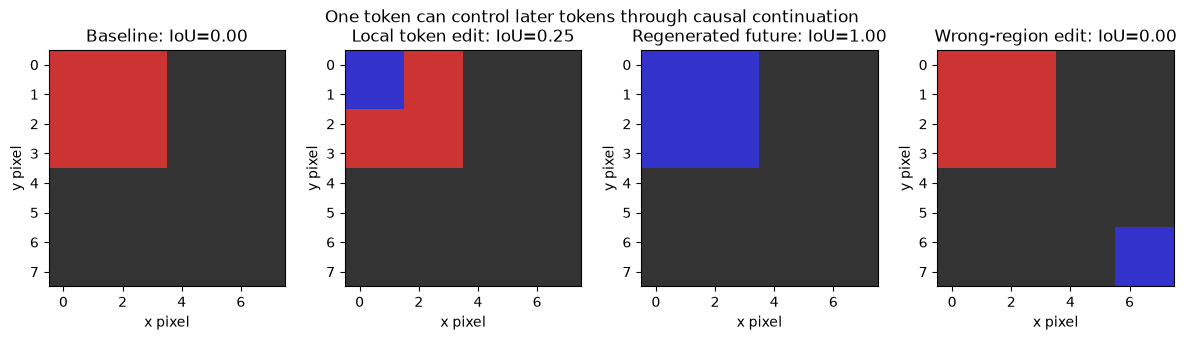

In [ ]:
local_grid=generated_red.copy();local_grid[0,0]=2
regenerated=regenerate_with_patch(1,layout,0,2)
wrong_region=generated_red.copy();wrong_region[-1,-1]=2
conditions=[generated_red,local_grid,regenerated,wrong_region]
images=[decode_tokens(c,codebook,2) for c in conditions]
truth_pixels=layout.repeat(2,axis=0).repeat(2,axis=1)
forced_patch=np.zeros((8,8),bool);forced_patch[:2,:2]=True
scores=[blue_mask_iou(image,truth_pixels) for image in images]
changed=[outside_patch_changes(images[0],image,forced_patch) for image in images]
print("Blue-object IoU base/local/regenerated/wrong-region:",scores)
print("Changed pixels outside first token:",changed)
utils.image_grid(images,[f"{name}: IoU={score:.2f}" for name,score in zip(["Baseline","Local token edit","Regenerated future","Wrong-region edit"],scores)],"One token can control later tokens through causal continuation")
plt.show()

<details><summary>Help - how should I interpret this?</summary>

Actual blue-object IoUs are0,0.25,1 and0. The regenerated image changes12 pixels outside the first token, whereas the local edit changes0 outside. The wrong-region edit changes4 background pixels but scores0 on the requested object. This image grid and causal influence count are the primary signature result; the program is an exact causal-copy organism, not a trained generative model.

</details>

## Try it yourself

Patch the **last** object token (raster position5) rather than the first. Predict the resulting
blue-object IoU and number of downstream changed pixels. The object layout and donor color
stay fixed. Then move the square right while preserving the raster ordering rule: which
prefix position should the first object query read?

In [ ]:
play_position=5
play_grid=regenerate_with_patch(1,layout,play_position,2)
play_image=decode_tokens(play_grid,codebook,2)
print("Late-patch blue IoU:",blue_mask_iou(play_image,truth_pixels))
utils.image_grid([images[0],play_image],["Baseline","Last object token forced blue"],"Forecast causal reach before patching")
plt.show()

## Summary of 4️⃣

Local decoding and causal regeneration answer different questions. The metric must name the object and region, and a visible color change outside that object should fail.

# ☆ Bonus

## Limits and the model bridge

This study edition teaches
quantization, decoding, VQ gradient routes, codebook usage, causal attention, autoregressive
feedback and image-token interventions with pixel-level scoring. Training a neural VQ-VAE
and an autoregressive transformer remains pending. No optimizer, learned checkpoint, tokenizer
training corpus or claim of image-distribution learning is supplied.

VQ-VAE learns discrete latent representations and an autoregressive prior. Taming Transformers
combines a learned image vocabulary with transformer composition. Our patch-mean encoder and
fixed codebook omit learned spatial compression, perceptual/adversarial objectives and a
learned prior. The known layout is a particularly strong form of supplied structure.

A native extension needs a declared training/selection/evaluation split; learned codebook and
reconstruction quality; autoregressive likelihood and decoded image quality; causal masking
checks; donor/recipient patches at matched spatial locations; and controls that separate
local decoded changes from regenerated downstream content. Record empty/unused codes instead
of hiding them behind an average reconstruction error.

## Further reading

- [Neural Discrete Representation Learning (VQ-VAE)](https://arxiv.org/abs/1711.00937).
- [Taming Transformers for High-Resolution Image Synthesis](https://arxiv.org/abs/2012.09841).
- [Official Taming Transformers code](https://github.com/CompVis/taming-transformers).